In [1]:
import os
# from fair import FAIR
# from fair.io import read_properties
# from fair.interface import initialise
# from fair.structure.units import desired_emissions_units
import numpy as np
import pandas as pd


import xarray as xr
from pathlib import Path
import glob
from drawdown import DATA_DIR
from drawdown import kernels
import string
import pandas as pd
import datetime
from utils import zenodo, CEDS
from drawdown import explorer
from drawdown.waste_stacking import waste_solutions

random_seed=123


from scipy.optimize import brentq

import matplotlib.cm as cm
import seaborn as sns
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings('ignore')

In [2]:
baseline_scenario="constant"
aerosol_scenario="low"

# How fast does a solution work?
How fast does a brake act on the global temperature? There are three timescales here: 
* deployment speed (how fast can we do it?).  For example, O&G methane can be quickly abated, but it takes a while to implement dietary change.
* emissions speed (over what timescale do unabated emissions occur?) For example, methane emissions from O&G infrastructure are immediately released, but a ton of OSW in landfill leaks out methane gradually.
* action speed (how fast does the solution act in the atmosphere).  This is a function of the species emitted: CH4 solutions act faster than CO2 solutions, and solutions targeting F-gases can act faster still.
### Total time
The total time for a solution to work is the convolution of these three scales.  Deployment, emission timing, atmospheric lifetime and climate response act in sequence, so their average delays add.

## Deployment speed
We split solutions up into three buckets according to how quickly they may be implemented

### Fast solutions
Abating coal mine and oil and gas methane can be done quickly.  We estimate that in an aggressively optimistic scenario the world can be halfway to maximum adoption within 3 years.

In [3]:
fast_time=3

### Medium solutions
While solutions may be deployed immediately on any given landfill or rice paddy, these are scattered all over the globe, and it will take more time to implement on large spatial scales.  We therefore estimate that the world can be halfway to maximum adoption within 7 years.

In [4]:
medium_time=7

## Slow solutions
Increasing centralized composting, reducing food loss and waste, and improving diets are large-scale social changes that take time.  We therefore estimate that it will take at least 12 years to be halfway to maximum achievable adoption of these solutions.

In [5]:
slow_time=12

## Emissions speed
### CMM and O&G methane
This is trivial: preventing methane relase means avoiding immediate emissions.
### Improve Diets
Enteric methane isn't reduced when we stop eating meat, it's reduced when herds shrink.  We assume this lags demand changes by about a year and a half, and use an exponential to model several processes: slaughter, reductions in breeding, etc.
### Waste Solutions
All of our waste solutions fundamentally act on the same pool of landfill methane, so we can't just stack them.  Biocovers and landfill methane capture reduce the emissions from a given ton of OSW, while composting and reducing food loss/waste reduces the tonnage of OSW in landfill.  We'll model this as 
$$ emitted(t) = [E_0 - C(t)] \times [1 - f_{cap}(t)] \times [1 - f_{bio}(t)]$$
        $$reduction(t)  = E_0 - emitted(t)$$
where $E_0=70$ Mt yr$^{-1}$ is the current landfill methane emission rate, $C(t)$ is the methane emissions avoided by keeping stuff out of landfill (composting or reducing FLW) and  $f_{cap}(t)$ and $f_{bio}(t)$ are the fractions of methane emissions captured and oxidized by biocovers, respectively.

We use a first-order decay model for the emitted methane, assuming it leaks out gradually.  The annual fractions of a ton's lifetime landfill CH4 emitted j years after deposit is
 $$ h(j) = e^{-k j} - e^{-k (j + 1)}$$
 $$ \sum_j h(j) = 1$$

#### Modeling Avoided FLW 
Right now Drawdown reports climate benefit from reducing FLW in terms of CO2eq-100.  Crippa et al (2021) report food system emissions are ~35% CH4, ~55% CO2, ~10% N20, which we assume apply to food loss and waste.  If Improve Diets is implemented, we assume food system emissions are ~90% CO2, because we assume Improve Diets completely reduces meat/dairy in the food loss pipeline.  

#### Modeling Improve Diets
Improving diets reduces methane emissions but also avoids deforestation.  Since we will later look at the impacts of reduced deforestation, we set AFOLU CO2 reduced by the Improve Diets solution to 0.

## Action speed
The speed of action is determined by physics and depends on a) the breakdown of species emitted (CH4, CO2, N2O etc)  b) the background climate state (e.g. in a reduced NOx environment methane is longer-lived) and c) the climate response (sensitivity to emissions).  These are handled by the FAIR climate model.

# Summary of modeling choices
| Solution | Speed | years to half adoption | S-curve k | AU | Kernel  | Notes |
|---|---|---|---|---|---|---|
| Oil & gas methane | Fast | 3 | 1.0 | Mt CH₄/yr abated | δ | Acts immediately, directly on methane |
| Coal-mine methane | Fast | 3 | 1.0 | Mt CH₄/yr abated | δ | Acts immediately, directly on methane |
| Landfill capture | Medium | 7 | 0.5 | Fraction of the pool (level) | In `waste_solutions` | Applied after the convolution, as $(E_0 - C)(1 - f_c)(1 - f_b)$. |
| Landfill biocovers | Medium | 7 | 0.5 | Fraction of the pool (level) | None: multiplicative | As above. Already in `waste_solutions`. |
| Alternative refrigerants | Medium | 7 | 0.5 | kt of bank switched (stock) | δ on the stock × annual leak rate | SARAH |
| Alternative insulation | Medium | 7 | 0.5 | Units installed (convert to new units per yr) | SARAH|
| Rice production | Medium | 7 | 0.5 | ha under AWD (level) | δ | Effect is within the season. Per-hectare CH₄ from the CSV, which needs a species split (currently blank). |
| Composting | Slow | 12 | 0.3 | dry t diverted per yr (flow) | First-order decay, rate k | Already in `waste_solutions`. |
| Food Loss & Waste | Slow | 12 | 0.3 | t avoided per yr (flow) | δ for production; decay for the landfilled share | Already in `waste_solutions`. |
| Improve Diets | Slow | 12 | 0.3 | kg meat avoided per yr (level) | Short exponential, τ ≈ 1–2 yr | Herd-adjustment lag. CH₄ = 1.29 kg per kg meat (44–55 Mt at high adoption). CO₂ as AFOLU. |

**MANAGING CONFLICTS** 
If both Improve Diets and Reduce Food Loss and Waste are included, we assume
  Improve Diets' adoption fully accounts for all the ruminant-meat/dairy-driven
  methane in the Food Loss/Waste solution.  That is, right now we assume that CH4 emissions account for 35% of food system GHG emissions (CO2e).  If we both reduce FLW *and* improve diets we're risking double counting methane reductions: we're throwing away less food, but the food we throw away is also less methane-intensive.  We'll assume implementation of Improve Diets means the food thrown away is essentially zero meat and dairy.

  Additionally, if both improve diets and protect forests, there's a risk of double counting since Drawdown assesses that "improve diets" will lead to reduced deforestation.  We'll deal with that by removing the AFOLU CO2 emissions from improve diets

In [6]:
 from drawdown import kernels

In [7]:
import numpy as np
from drawdown import explorer, kernels
from drawdown.explorer import S_curve

t = kernels.TIMEPOINTS
n = len(t)

# --- deployment speed classes (logistic S-curve) -------------------------
SPEED = {"fast":   {"years_to_half_adoption": fast_time,  "k": 1.0},   # ~90% by start+5
         "medium": {"years_to_half_adoption": medium_time,  "k": 0.5},   # ~90% by start+11
         "slow":   {"years_to_half_adoption": slow_time, "k": 0.3}}   # ~90% by start+19

# --- ADDITIONAL adoption at saturation (high achievable)---
E0 = 69.56                      # Mt CH4/yr landfill pool (Drawdown / IEA 2025)
ADD = {
    # Mt CH4/yr abated. ADOPTION CEILINGS (~whole sector)
    "Manage Oil & Gas Methane": 44.,
    "Manage Coal Mine Methane": 21,
    # fractions of the landfill pool (Drawdown high achievable / E0)
    "landfill capture":   (34.78) / E0,
    "landfill biocovers": 57.04 / E0,           # current adoption not determined
    # dry t/yr: 301 Mt high achievable minus 78 Mt current, wet -> dry
    "composting": (301e6 ) * (1 - 0.6),
    # wet t/yr avoided (50% cut; current not determined)
    "food loss & waste": 875e6,
    # kg ruminant meat avoided per yr
    "Improve Diets": 42.9e9,
}
HERD_LAG_YR = 1.5               # diets: exponential lag tau

In [58]:
def curve(L, speed, start):
    return S_curve(t, start, L, **SPEED[speed])


def stack(*dicts):
    """Sum species-wise across perturbation dicts {specie: array}."""
    out = {}
    for d in dicts:
        for sp, ts in d.items():
            out[sp] = out.get(sp, 0.0) + ts
    return out


def build_brakes(start=2026, suffix=""):
    """One perturbation dict per brake, per speed class, and the full stack."""
    p = {}

    # FAST: delta kernel, straight from get_input
    for sol in ["Manage Oil & Gas Methane", "Manage Coal Mine Methane"]:
        p.update(explorer.get_input(sol, S_curve, ADD[sol], start,
                                    function_kwargs=SPEED["fast"],
                                    scenario_name=sol + suffix))

    # MEDIUM: landfill capture + biocovers (multiplicative on the pool)
    fc = curve(ADD["landfill capture"], "medium", start)
    fb = curve(ADD["landfill biocovers"], "medium", start)
    # SLOW: composting + FLW (first-order decay) -- same pool
    comp = curve(ADD["composting"], "slow", start)
    flw = curve(ADD["food loss & waste"], "slow", start)

    p.update(kernels.waste_solutions(capture=fc, scenario_name="Landfill capture" + suffix))
    p.update(kernels.waste_solutions(biocovers=fb, scenario_name="Landfill biocovers" + suffix))
    p.update(kernels.waste_solutions(composting=comp, scenario_name="Composting" + suffix))
    p.update(kernels.waste_solutions(food_loss_waste=flw, scenario_name="Food loss & waste" + suffix))
    waste_stack = kernels.waste_solutions(capture=fc, biocovers=fb, composting=comp,
                                          food_loss_waste=flw, scenario_name="w",diets_claims_flw_ch4=True,ecosystems_claim_flw_afolu=True)["w"]

    p["All waste" + suffix] = waste_stack
    
    # SLOW: diets -- get_input, then herd-adjustment lag kernel
    d = explorer.get_input("Improve Diets", S_curve, ADD["Improve Diets"], start,
                         land=True, function_kwargs=SPEED["slow"],
                         scenario_name="Improve Diets")["Improve Diets"]
    # Diets is treated as enabling-only: it lowers the food system's GHG intensity
    # (fewer ruminants -> less enteric/manure CH4) directly. Remove the AFOLU CO2 emissions avoided- 
    # we'll account for those in reduced deforestation
    d = {sp: ts for sp, ts in d.items() if sp != "CO2 AFOLU"}
    h = kernels.exp_kernel(n, HERD_LAG_YR)
    diets = {sp: np.convolve(ts, h)[:n] for sp, ts in d.items()}
    p["Improve Diets" + suffix] = diets

    # speed-class subtotals and the full stack (waste interactions kept)
    p["Fast brakes" + suffix] = stack(p["Manage Oil & Gas Methane" + suffix],
                                      p["Manage Coal Mine Methane" + suffix])
    p["All brakes" + suffix] = stack(p["Fast brakes" + suffix], waste_stack, diets)
    return p

In [61]:
from importlib import reload
reload(kernels)

<module 'drawdown.kernels' from '/Users/katemarvel/Documents/DrawdownImpacts/drawdown/kernels.py'>

In [62]:
# pull the brakes this year
perts = build_brakes(2027)
# pull them in a decade
delayed = build_brakes(2037, suffix=" (2036)")
perts["All brakes (2036)"] = delayed["All brakes (2036)"]


In [63]:
perts["All brakes"]["CO2 AFOLU"]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [64]:
f = explorer.drawdown_model(baseline_scenario, perts, lite=True, n_lite=50)

Running 600 projections in parallel:   0%|          | 0/352 [00:00<?, ?timesteps/s]

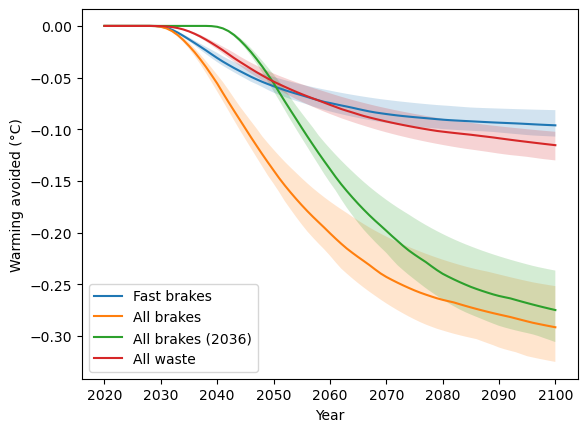

In [65]:
explorer.plot_T_diff(f, end_time=2100,
                     scenarios=["Fast brakes", "All brakes", "All brakes (2036)","All waste"])

## How well do the brakes work? Slowing down global warming
The plot above shows the warming avoided in °C. To compare brakes against aerosol unmasking, we'll instead look at how each one changes the warming *rate* (°C/decade) in a given year (relative to the baseline scenario).


dT/dt comes from a Savitzky–Golay filter (same method as `smoothed_rate_of_change` in AllSolutions.ipynb / Aerosols_101626.ipynb).

Change in warming rate in 2035, relative to 'constant':
Fast brakes                  -0.032 degC/decade (IQR -0.036 to -0.027)
All brakes                   -0.056 degC/decade (IQR -0.064 to -0.048)
All brakes (2036)            -0.000 degC/decade (IQR -0.001 to -0.000)


Text(0.5, 1.0, 'Change in warming rate in 2035 relative to constant 2024 emissions (°C/decade)')

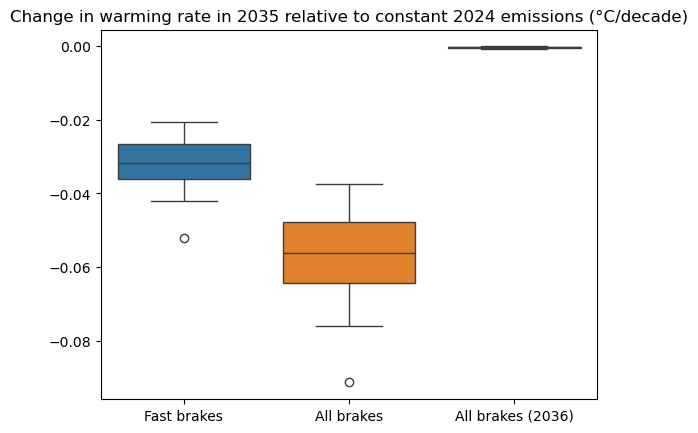

In [66]:
from scipy.signal import savgol_filter

def smoothed_rate_of_change(T, window_length=11, polyorder=2):
    """
    Smoothed dT/dt (units of T per year) along "timebounds", using a
    Savitzky-Golay filter rather than T.diff().
    window_length is in years (odd, > polyorder).
    """
    timebounds = T.timebounds.values
    dt = np.median(np.diff(timebounds))
    rate = xr.apply_ufunc(
        savgol_filter,
        T,
        input_core_dims=[["timebounds"]],
        output_core_dims=[["timebounds"]],
        kwargs=dict(window_length=window_length, polyorder=polyorder, deriv=1, delta=dt),
    )
    return rate.assign_coords(timebounds=timebounds)


def warming_rate_change(f, scenario, year=None, reference_scenario=None,
                        window_length=11, polyorder=2):
    """
    Change in the warming rate (degC/decade) in `scenario` relative to
    `reference_scenario` (default f.baseline_scenario).  Negative means
    the scenario slows warming (brakes); positive means it speeds it up
    (aerosol unmasking).

    year: a single year, or None for the whole timeseries.

    Returns an xr.Dataset (each variable has a "config" dimension) with
      rate_reference  reference warming rate (degC/decade)
      rate_scenario   warming rate in `scenario` (degC/decade)
      rate_change     rate_scenario - rate_reference
    """
    if reference_scenario is None:
        reference_scenario = f.baseline_scenario
    rates = {}
    for name, scen in [("rate_reference", reference_scenario),
                       ("rate_scenario", scenario)]:
        # x10: per year -> per decade; drop the scalar "scenario" coord,
        # which differs between the two and would clash in the Dataset
        rate = 10 * smoothed_rate_of_change(f.temperature.sel(scenario=scen, layer=0),
                                            window_length, polyorder)
        if year is not None:
            rate = rate.sel(timebounds=year, method="nearest")
        rates[name] = rate.drop_vars("scenario")
    return xr.Dataset(rates | {"rate_change": rates["rate_scenario"] - rates["rate_reference"]})


def brake_aerosol_decomposition(f, brake_scenario, aerosol_scenario_name,
                                combined_scenario, year=None, **kwargs):
    """
    Deceleration from the brakes, acceleration from aerosols, and the net
    from running both together, all from one FaIR run `f` (so the configs
    line up).  Each is rate_change vs f.baseline_scenario, in degC/decade.

      brakes        rate change from `brake_scenario` alone (< 0)
      aerosols      rate change from `aerosol_scenario_name` alone (> 0)
      net           rate change from `combined_scenario`
      additive      brakes + aerosols (what you'd get with no interactions)
      nonlinearity  net - additive
    """
    rc = lambda s: warming_rate_change(f, s, year, **kwargs).rate_change
    out = xr.Dataset({"brakes": rc(brake_scenario),
                      "aerosols": rc(aerosol_scenario_name),
                      "net": rc(combined_scenario)})
    out["additive"] = out.brakes + out.aerosols
    out["nonlinearity"] = out.net - out.additive
    return out


def summarize(da, label):
    q = da.quantile([0.25, 0.5, 0.75], dim="config").values
    print(f"{label:28s} {q[1]:+.3f} degC/decade (IQR {q[0]:+.3f} to {q[2]:+.3f})")


year = 2035
arr=np.zeros((3,len(f.configs.values)))
i=0
print(f"Change in warming rate in {year}, relative to '{baseline_scenario}':")
for scen in ["Fast brakes", "All brakes", "All brakes (2036)"]:
    summarize(warming_rate_change(f, scen, year).rate_change, scen)
    arr[i]=(warming_rate_change(f, scen, year).rate_change)
    i+=1
sns.boxplot(arr.T)
plt.gca().set_xticklabels(["Fast brakes", "All brakes", "All brakes (2036)"])
plt.title(f"Change in warming rate in {year} relative to constant 2024 emissions (°C/decade)")

# Why act fast?
Aerosol emissions are declining and warming is/will be accelerating as a result.


Read in the emissions of different aerosol species 

In [14]:

arr=CEDS._CEDS_species
to_remove=["CH4","CO2"]
CEDS_aerosols= arr[~np.isin(arr, to_remove)]
aerosol_species=[CEDS.CEDS_name_to_FAIR(x) for x in CEDS_aerosols]

In [15]:

low_aerosol_dict={}
for specie in aerosol_species:
    low_aerosol_dict[specie]=aerosol_scenario
highlow_dict={f"{aerosol_scenario}-allaer":low_aerosol_dict}
for specie in aerosol_species:
    highlow_dict[f"{aerosol_scenario}-{specie}"]={specie:aerosol_scenario}

In [16]:
# dictionary of dictionaries
aerosol_reductions=explorer.scenarios_to_emissions(baseline_scenario,{f"{aerosol_scenario}-allaer":low_aerosol_dict})
#just the components without the scenario name
aerosols_only=aerosol_reductions[f"{aerosol_scenario}-allaer"]

In [17]:
test=stack(aerosols_only,perts["All brakes"])

In [18]:
perts[f"{aerosol_scenario}-allaer + All brakes"]=stack(aerosols_only,perts["All brakes"])
perts[f"{aerosol_scenario}-allaer"]=aerosols_only

In [19]:
f = explorer.drawdown_model(baseline_scenario, perts, lite=True, n_lite=50, emissions_year=2024)
#f2020 = explorer.drawdown_model(baseline_scenario, perts, lite=True, n_lite=10, emissions_year=2020)

Running 700 projections in parallel:   0%|          | 0/352 [00:00<?, ?timesteps/s]

Pulling all the brakes can reduce the speed of aerosol-induced warming

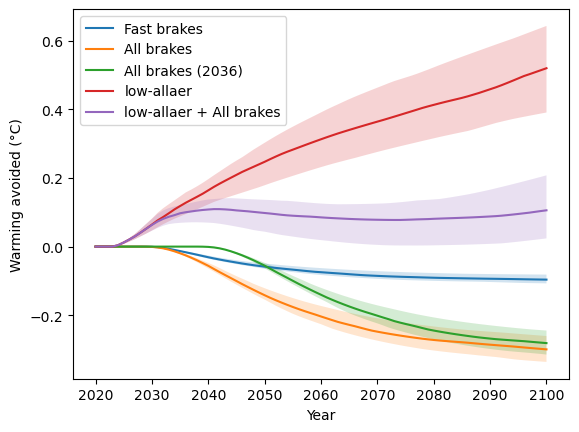

In [20]:
explorer.plot_T_diff(f, end_time=2100,
                     scenarios=["Fast brakes", 
                                "All brakes", "All brakes (2036)",
                                f"{aerosol_scenario}-allaer",
                                f"{aerosol_scenario}-allaer + All brakes"])
#plt.xlim(2027,2050)

In [21]:
# year=2035
# for scen in f.scenarios:
#     summarize(warming_rate_change(f, scen, year).rate_change, scen)

# Pulling the brakes
How much can we slow down the aerosol-unmasked warming by 2035?

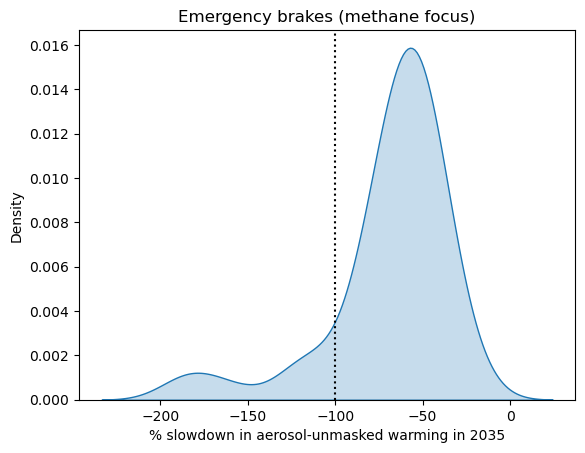

In [22]:
rate_allbrakes=warming_rate_change(f,f"{aerosol_scenario}-allaer + All brakes",2035).rate_change
rate_unmask=warming_rate_change(f,f"{aerosol_scenario}-allaer",2035).rate_change
pct=(100*((rate_allbrakes-rate_unmask)/rate_unmask))#.plot.hist()
sns.kdeplot(pct,fill=True)
plt.xlabel("% slowdown in aerosol-unmasked warming in 2035")
plt.title("Emergency brakes (methane focus)")
plt.axvline(-100,ls=":",c="k")

In [23]:
#It's only a 7% reduction! I just don't see how a 30% cut would be possible
i=kernels.TIMEPOINTS.tolist().index(2030)
ch42020=f.emissions.sel(timepoints=2020,method="nearest").sel(specie="CH4",\
                                                                   scenario=baseline_scenario).isel(config=0)

ch42030=f.emissions.sel(timepoints=2030,method="nearest").sel(specie="CH4",\
                                                                   scenario="All brakes").isel(config=0)

print("It's a ", float((ch42020-ch42030)/ch42020)*100, "% reduction")

It's a  6.934497408307967 % reduction


The GAINS MTFR scenario shows that existing technologies could reduce anthropogenic methane emissions 32% below 2020 by 2030, meeting the Global Methane Pledge. This is a technical-potential estimate that assumes full deployment by 2030. When the same class of measures is deployed along optimistic but finite adoption curves beginning in 2027, emissions fall only ~7% below 2020 by 2030, consistent with GAINS’s own NDCs & MAPs scenario (8%). Meeting the pledge would require deployment roughly three times faster than our already optimistic assumptions. The methane brakes are large enough to offset aerosol unmasking eventually; the binding constraint is deployment time, which is why delay is costly.

# Adding in the land emergency brakes


In [24]:
forest_adoption_speed="fast"
adoption_curve = explorer.S_curve
year_implemented = 2027

forest_dict={}
for climate_zone in ["boreal","subtropical","temperate","tropical"]:
    scenario_name = f"Protect Forests: {climate_zone.capitalize()}"
    #hectares_protected=1.
    hectares_protected = explorer.achievable_adoption(\
    scenario_name,"high")
    forest_dict = forest_dict | kernels.get_land_input(kernels.forest_emissions, \
                                           climate_zone, \
                                           adoption_curve, \
                                           hectares_protected,\
                                           year_implemented, \
                                           function_kwargs=SPEED[forest_adoption_speed], \
                                           ecosystem_kwargs={},\
                                           scenario_name=scenario_name)

forest_dict["All forests"] = stack(*[item for k,item in forest_dict.items()])

# --- Peatlands and Grasslands & Savannas: same per-climate-zone pattern as forests ---
climate_zones = ["boreal","subtropical","temperate","tropical"]

peatland_keys = []
for climate_zone in climate_zones:
    scenario_name = f"Protect Peatlands: {climate_zone.capitalize()}"
    hectares_protected = explorer.achievable_adoption(scenario_name,"high")
    forest_dict = forest_dict | kernels.get_land_input(kernels.peatland_emissions,
                                           climate_zone, adoption_curve, hectares_protected,
                                           year_implemented, function_kwargs=SPEED[forest_adoption_speed],
                                           ecosystem_kwargs={}, scenario_name=scenario_name)
    peatland_keys.append(scenario_name)
forest_dict["All peatlands"] = stack(*[forest_dict[k] for k in peatland_keys])

grassland_keys = []
for climate_zone in climate_zones:
    scenario_name = f"Protect Grasslands and Savannas: {climate_zone.capitalize()}"
    hectares_protected = explorer.achievable_adoption(scenario_name,"high")
    # grassland_emissions takes no deforestation_model kwarg -- ecosystem_kwargs stays {}
    forest_dict = forest_dict | kernels.get_land_input(kernels.grassland_emissions,
                                           climate_zone, adoption_curve, hectares_protected,
                                           year_implemented, function_kwargs=SPEED[forest_adoption_speed],
                                           ecosystem_kwargs={}, scenario_name=scenario_name)
    grassland_keys.append(scenario_name)
forest_dict["All grasslands"] = stack(*[forest_dict[k] for k in grassland_keys])

# --- Seaweed: one global adoption ceiling (no climate-zone split on the Explorer
# website), but protect_solutions tracks two macroalgae types -- split the
# hectares 50/50 across them, same treatment as Aerosols_101626.ipynb's
# build_land_protection_inputs ---
seaweed_scenario = "Protect Seaweed Ecosystems"
seaweed_hectares = explorer.achievable_adoption(seaweed_scenario,"high")
macroalgae_types = kernels.read_seaweed_data()["macroalgae_type"].tolist()
seaweed_keys = []
for macroalgae_type in macroalgae_types:
    key = f"{seaweed_scenario}: {macroalgae_type}"
    forest_dict = forest_dict | kernels.get_land_input(kernels.seaweed_emissions,
                                           macroalgae_type, adoption_curve,
                                           seaweed_hectares/len(macroalgae_types),
                                           year_implemented, function_kwargs=SPEED[forest_adoption_speed],
                                           ecosystem_kwargs={}, scenario_name=key)
    seaweed_keys.append(key)
forest_dict["All seaweed"] = stack(*[forest_dict[k] for k in seaweed_keys])

# --- combine every ecosystem, and against the aerosol-unmasking backdrop ---
forest_dict["All land protection"] = stack(forest_dict["All forests"], forest_dict["All peatlands"],
                                           forest_dict["All grasslands"], forest_dict["All seaweed"])
forest_dict[f"All land protection + {aerosol_scenario}-allaer"] = stack(forest_dict["All land protection"],
                                                                        aerosols_only)

forest_dict["All land protection + All brakes"] = stack(forest_dict["All land protection"],perts["All brakes"])
forest_dict[f"All land protection + All brakes + {aerosol_scenario}-allaer"]=stack(forest_dict["All land protection + All brakes"] ,
                                                                           perts[f"{aerosol_scenario}-allaer"])
forest_dict[f"{aerosol_scenario}-allaer + All brakes"]=stack(aerosols_only,perts["All brakes"])
forest_dict[f"{aerosol_scenario}-allaer"]=aerosols_only

In [25]:
forest_f= explorer.drawdown_model("constant",forest_dict,lite=True,n_lite=50)

Running 1250 projections in parallel:   0%|          | 0/352 [00:00<?, ?timesteps/s]

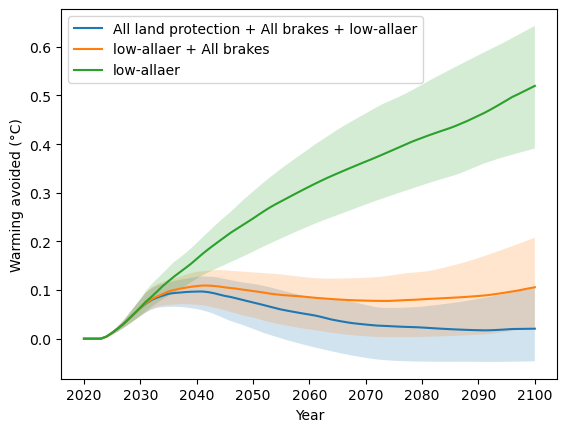

In [26]:
explorer.plot_T_diff(forest_f,scenarios=[f"All land protection + All brakes + {aerosol_scenario}-allaer", 
                                         "low-allaer + All brakes",
                                         "low-allaer"
])

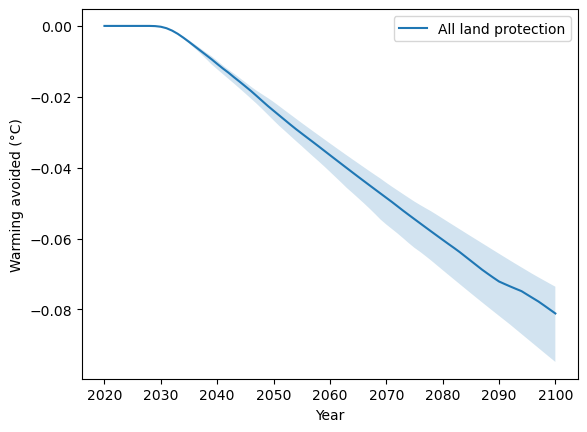

In [32]:
explorer.plot_T_diff(forest_f,scenarios=["All land protection"])

<xarray.DataArray 'specie' ()> Size: 172B
array('CO2 AFOLU', dtype='<U43')
Coordinates:
    config   int64 8B 951519
    specie   <U43 172B 'CO2 AFOLU'

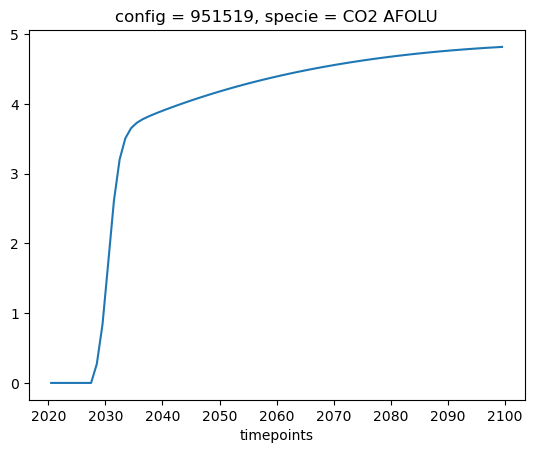

In [36]:
co2em=forest_f.emissions.sel(specie="CO2 AFOLU",
                      timepoints=slice(2020,2100)).isel(config=0)
(co2em.sel(scenario=baseline_scenario)-co2em.sel(scenario="All land protection")).plot()
co2em.specie

Text(0.5, 1.0, 'Emergency brakes (methane solutions + fast land action)')

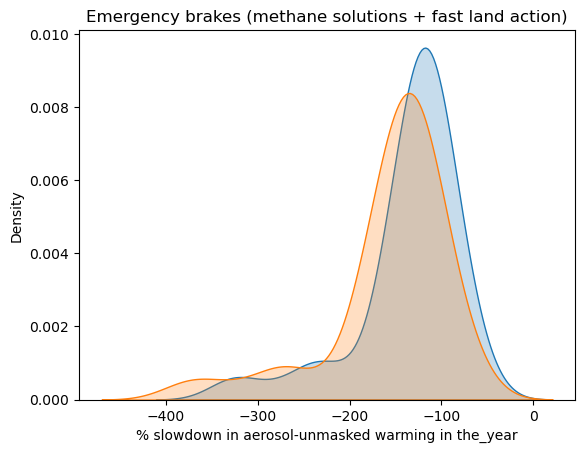

In [27]:
the_year=2050

rate_allbrakes=warming_rate_change(forest_f,f"{aerosol_scenario}-allaer + All brakes",the_year).rate_change
rate_unmask=warming_rate_change(forest_f,f"{aerosol_scenario}-allaer",the_year).rate_change
pct=(100*((rate_allbrakes-rate_unmask)/rate_unmask))#.plot.hist()

rate_allbrakesplusland=warming_rate_change(forest_f,f"All land protection + All brakes + {aerosol_scenario}-allaer",the_year).rate_change
rate_unmaskplusland=warming_rate_change(forest_f,f"{aerosol_scenario}-allaer",the_year).rate_change
pctplusland=(100*((rate_allbrakesplusland-rate_unmaskplusland)/rate_unmask))#.plot.hist()

sns.kdeplot(pct,fill=True)
sns.kdeplot(pctplusland,fill=True)
plt.xlabel("% slowdown in aerosol-unmasked warming in the_year")
plt.title("Emergency brakes (methane solutions + fast land action)")

In [28]:
rate_allbrakesplusland=warming_rate_change(forest_f,f"All land protection + All brakes + {aerosol_scenario}-allaer",2035).rate_change
rate_unmaskplusland=warming_rate_change(forest_f,f"{aerosol_scenario}-allaer",2035).rate_change
pctplusland=(100*((rate_allbrakesplusland-rate_unmaskplusland)/rate_unmask))#.plot.hist()

1. Write technical paper for scientific journal
2. Punchier commentary piece that cites other paper for methods